In [9]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib as mpl
import pylab as plt
import copy
import os
from scipy.interpolate import interp1d
import pickle
from random import choices, getrandbits
from Grids import *
import BoltzEvolve

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [10]:
ThermVelNormUnits

50.85272854036448

In [11]:
T=1           # in K
kT=T*8.62e-5  # in eV
mp=6e9        # in eV

ThermMom=np.sqrt(2*mp*kT) # in eV
ThermVel=ThermMom/mp      # in c

ThermVelNormUnits=ThermVel*3e8 # in ms^-1
#Density=1e18/(215*1e-4)*(0.27/2)        # in m^-3 (lifted from CDR)
Density  = 6.28e18
CrossSec = 7.2e-17    # in m2


RateConst=ThermVelNormUnits*Density*CrossSec

size=30
grid=Grid2D(size)

6.259024585120978e+18


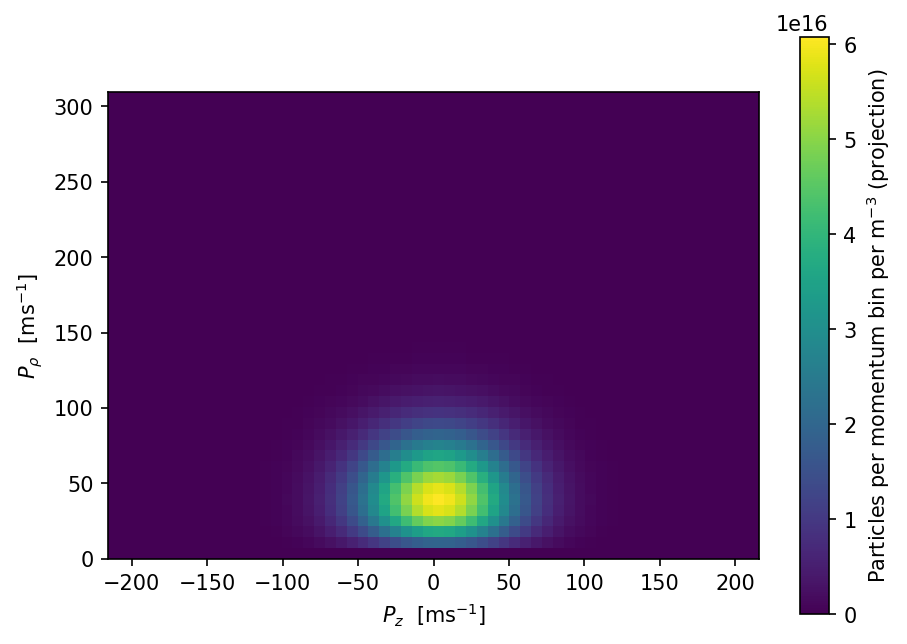

In [12]:
mkt=25  #MBDE p^2 for 1 sigma, in grid untis
dist=SlicedMB2D(T=T, mkt=mkt, gridpoints=size, m=mp, RCut=35,Rho=Density)
plt.figure(figsize=(7,5),dpi=150)
plt.imshow((dist.f*dist.grid.RR2).T,origin='lower',extent=(-dist.grid.zlim*dist.VScale_SI(),dist.grid.zlim*dist.VScale_SI(),0,dist.grid.rlim*dist.VScale_SI()))
plt.colorbar(label=r'Particles per momentum bin per m$^{-3}$ (projection)')

plt.ylabel(r"$P_\rho$  [ms$^{-1}$]")
plt.xlabel(r"$P_z$  [ms$^{-1}$]")
Tot=sum(sum(dist.f*dist.grid.RR2))
print(Tot)

6.259024585120978e+18


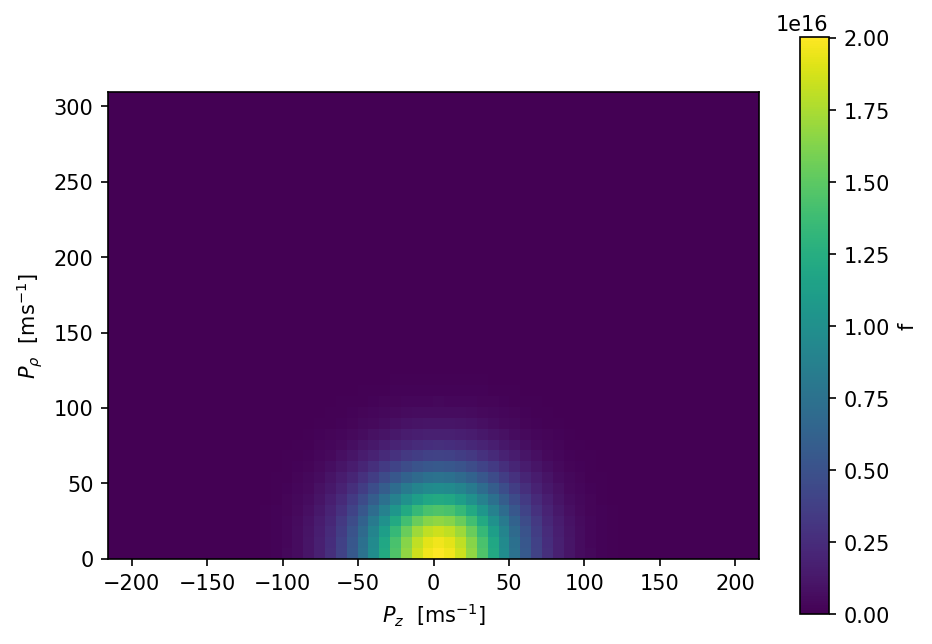

In [13]:
mkt=25  #MBDE p^2 for 1 sigma, in grid untis
#dist=SlicedMB2D(T=T, MBSigma2=SqrtTwoMKT**2, gridpoints=size, m=mp, RCut=35,Rho=Density)
plt.figure(figsize=(7,5),dpi=150)
plt.imshow((dist.f).T,origin='lower',extent=(-dist.grid.zlim*dist.VScale_SI(),dist.grid.zlim*dist.VScale_SI(),0,dist.grid.rlim*dist.VScale_SI()))
plt.colorbar(label=r'f')

plt.ylabel(r"$P_\rho$  [ms$^{-1}$]")
plt.xlabel(r"$P_z$  [ms$^{-1}$]")
Tot=sum(sum(dist.f*dist.grid.RR2))
print(Tot)

In [14]:
be=BoltzEvolve.Evolver2D(grid,verbose=True,CrossSec=CrossSec)



In [15]:
def GetParticleAndEnergyRates(dist,Thresh=18,cols=500):
    c2=grid.RR2**2+grid.ZZ2**2

    CutMask=grid.RR2<Thresh
    InvCutMask=np.ones_like(CutMask)-CutMask.astype('int')
    DensityCorrection=sum(sum(dist.f*grid.RR2))/sum(sum(dist.f*CutMask*grid.RR2))
    dist.f=dist.f*CutMask*DensityCorrection
    dfdt=be.GetDfDtFast(dist, cols)

#    print("N")
#    print(sum(sum(dfdt*InvCutMask*grid.RR2)),sum(sum(dist.f*grid.RR2)))
#    print("E")
#    print(sum(sum(c2*dfdt*InvCutMask*grid.RR2)),sum(sum(c2*dist.f*grid.RR2)))
    particlefrac = sum(sum(dfdt*InvCutMask*grid.RR2))/sum(sum(dist.f*grid.RR2))
    energyfrac   = sum(sum(c2*dfdt*InvCutMask*grid.RR2))/sum(sum(c2*dist.f*grid.RR2))
#    plt.imshow(dfdt*grid.RR2,cmap='RdBu')
#    plt.title('dfdt')
#    plt.clim(-6e17,6e17)
#    plt.colorbar()
#    plt.show()
#    plt.imshow(dist.f*grid.RR2)
#    plt.title('dfdt')
#    plt.colorbar()
#    plt.show()
    return particlefrac,energyfrac

In [16]:
allparticlefracs=[]
allenergyfracs=[]
Densities=np.logspace(17,21,5)
#Densities=[Density]
Threshs=np.arange(10,30)

for d in Densities:
    print(d)
    particlefracs=[]
    energyfracs=[]
    for i in Threshs:

        print(i)
        dist=SlicedMB2D(T=T, mkt=mkt, gridpoints=size, m=mp, RCut=50,Rho=d)
        p,e=GetParticleAndEnergyRates(dist,i,1000)
        particlefracs.append(p)
        energyfracs.append(e)
    allparticlefracs.append(particlefracs)
    allenergyfracs.append(energyfracs)

1e+17
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
1e+18
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
1e+19
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
1e+20
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
1e+21
10


KeyboardInterrupt: 

In [ ]:
plt.figure(figsize=(5,5),dpi=200)
Cols=['DarkBlue','DarkRed','purple','black','darkgreen']
for i in range(0,len(allparticlefracs)):

    
    plt.plot((Threshs)**2/(mkt),np.array(allparticlefracs[i])/Densities[i],'-',label=r'$\rho$='+str(Densities[i]),color=Cols[i])
    plt.plot((Threshs)**2/(mkt),np.array(allenergyfracs[i])/Densities[i],'--',color=Cols[i])
plt.xlabel("Cut position units of (mkT)")
plt.ylabel(r"Fractional loss rate/$\sqrt{T}$  [$s^{-1} K^{-1/2}$]")
plt.legend(loc='lower left')
plt.title(r"Lithium, 1K")
#plt.xlim(1,9)
#plt.ylim(1e-1,1e3)

plt.semilogy()
#np.savetxt("./out/Tritium_1e18_T"+str(T)+".txt",[Threshs/DistPeak,np.array(particlefracs),np.array(energyfracs)])

In [ ]:
allparticlefracs=[]
allenergyfracs=[]
Temps=[0.01,0.1,1,10,100]
#Densities=[Density]
Threshs=np.arange(10,30)

for T in Temps:
    print(d)
    particlefracs=[]
    energyfracs=[]
    for i in Threshs:

        print(i)
        dist=SlicedMB2D(T=T, mkt=mkt, gridpoints=size, m=mp, RCut=50,Rho=1e18)
        p,e=GetParticleAndEnergyRates(dist,i,1000)
        particlefracs.append(p)
        energyfracs.append(e)
    allparticlefracs.append(particlefracs)
    allenergyfracs.append(energyfracs)

In [ ]:
plt.figure(figsize=(5,5),dpi=200)
Cols=['DarkBlue','DarkRed','purple','black','darkgreen']
for i in range(0,len(allparticlefracs)):

    
    plt.plot((Threshs)**2/(mkt),np.array(allparticlefracs[i])/np.sqrt(Temps[i]),'-',label=r'$T$='+str(Temps[i]) + "K",color=Cols[i])
    plt.plot((Threshs)**2/(mkt),np.array(allenergyfracs[i])/np.sqrt(Temps[i]),'--',color=Cols[i])
plt.xlabel("Cut position units of (mkT)")
plt.ylabel(r"Fractional loss rate/$\sqrt{T}$  [$s^{-1} K^{-1/2}$]")
plt.legend(loc='lower left')
plt.title(r"Tritium, $10^{18}m^{-3}$")
#plt.xlim(1,9)
#plt.ylim(1e-1,1e3)

plt.semilogy()

In [20]:
Threshs=np.arange(10,31)
particlefracs=[]
energyfracs=[]
for i in Threshs:
    print (i)
    dist=SlicedMB2D(T=1, mkt=mkt, gridpoints=size, m=mp, RCut=50,Rho=1e18)
    p,e=GetParticleAndEnergyRates(dist,i,1000)
    particlefracs.append(p)
    energyfracs.append(e)

10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30


In [21]:
LogGammaN=interp1d((Threshs)**2/(2*mkt),np.log(np.array(particlefracs)),bounds_error=False,fill_value='extrapolate')
LogGammaE=interp1d((Threshs)**2/(2*mkt),np.log(np.array(energyfracs)),bounds_error=False,fill_value='extrapolate')
GammaN=lambda eta: np.exp(LogGammaN(eta))
GammaE=lambda eta: np.exp(LogGammaE(eta))
#f=open("GammaFile_L1K_rho1e18.pkl",'wb')
#%pickle.dump([LogGammaE,LogGammaN],f)
#f.close()

In [18]:
#f=open("GammaFile_L1K_rho1e18.pkl",'rb')
#LogGammaE,LogGammaN=pickle.load(f)
#f.close()

<>:11: SyntaxWarning: invalid escape sequence '\e'
<>:11: SyntaxWarning: invalid escape sequence '\e'
/var/folders/vy/ll7qjbxx66v846pybl4qyvh80000gs/T/ipykernel_45423/1670492868.py:11: SyntaxWarning: invalid escape sequence '\e'
  plt.xlabel("$\eta_{cut}$")


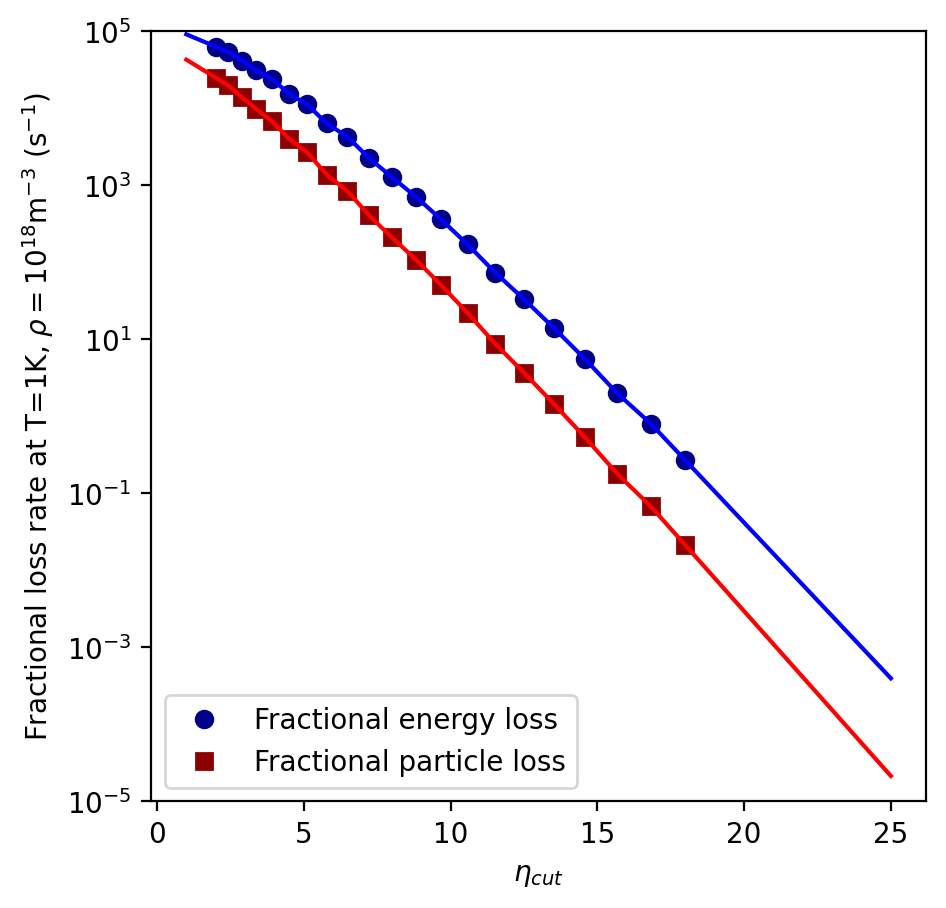

Bad pipe message: %s [b'\xde\x1d']
Bad pipe message: %s [b'O\xd9\x03\xb2?\xe9\x87\x18\x88d7O\xe3\x8d\x00\x01|\x00\x00\x00\x01\x00\x02\x00\x03\x00\x04\x00\x05\x00\x06\x00\x07\x00\x08\x00\t\x00\n\x00\x0b\x00\x0c\x00\r\x00\x0e\x00\x0f\x00\x10\x00\x11\x00\x12\x00\x13\x00\x14\x00\x15\x00\x16\x00\x17\x00\x18\x00\x19\x00\x1a\x00\x1b\x00/\x000\x001\x002\x003\x004\x005\x006\x007\x008\x009\x00:\x00;\x00<\x00=\x00>\x00?\x00@\x00A\x00B\x00C\x00D\x00E\x00F\x00g\x00h\x00i\x00j\x00k\x00l\x00', b'\x84\x00\x85\x00\x86\x00\x87\x00\x88\x00\x89\x00\x96\x00\x97\x00\x98\x00\x99\x00\x9a\x00\x9b\x00\x9c\x00\x9d\x00\x9e\x00\x9f\x00\xa0\x00\xa1\x00\xa2\x00\xa3\x00\xa4\x00\xa5\x00\xa6\x00\xa7\x00\xba\x00\xbb\x00\xbc\x00\xbd\x00\xbe\x00\xbf\x00\xc0\x00\xc1\x00\xc2\x00\xc3\x00\xc4\x00\xc5\x13\x01\x13\x02\x13\x03\x13\x04\x13\x05\xc0\x01\xc0\x02\xc0\x03\xc0\x04\xc0\x05\xc0\x06\xc0\x07\xc0\x08\xc0\t\xc0\n\xc0\x0b\xc0\x0c\xc0\r\xc0']
Bad pipe message: %s [b'\x0f\xc0\x10\xc0\x11\xc0\x12\xc0\x13\xc0\x14\xc0\x15']
Bad pi

In [30]:
plt.figure(figsize=(5,5),dpi=200)
Cols=['DarkBlue','DarkRed','purple','black','darkgreen']
    
etas=np.linspace(1,25,100)
plt.plot((Threshs)**2/(2*mkt),np.array(energyfracs),'o',label=r'Fractional energy loss',color='DarkBlue')
plt.plot((Threshs)**2/(2*mkt),np.array(particlefracs),'s',label=r'Fractional particle loss',color='DarkRed')


plt.plot(etas,GammaE(etas),'-',color='blue')
plt.plot(etas,GammaN(etas),'-',color='red')
plt.xlabel("$\eta_{cut}$")
plt.ylabel(r"Fractional loss rate at T=1K, $\rho=10^{18}$m$^{-3}$ (s$^{-1}$)")
plt.legend(loc='lower left')
#plt.title("Lithium")
#plt.title(r"Tritium, $10^{18}m^{-3}$")
#plt.xlim(1,9)
#plt.ylim(1e-1,1e3)
plt.ylim(1e-5,100000)
plt.semilogy()
plt.savefig("GammaPlot.png",dpi=200,bbox_inches='tight')

In [ ]:
plt.figure(figsize=(5,5),dpi=150)
plt.plot(L,effic,'o-',color='DarkRed',label=r'10$^{19}s^{-1}$')
plt.loglog()
plt.plot(LH,efficH,'o--',color='black',label=r'10$^{18}s^{-1}$')
plt.loglog()
plt.ylabel("Particle Efficiency")
plt.xlabel("Beamline length (m)")
plt.grid(which='both')
plt.legend(loc='lower right')

